<a href="https://colab.research.google.com/github/nafizzaazzahra07-ctrl/prediksi-harga-rumah-bekasi-XGBOOST/blob/main/Prediksi_Harga_Rumah_Bekasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 1: IMPORT LIBRARY & LOAD DATA
# ------------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Model Regresi & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

# 1.1 Load Data (Upload file ke Colab atau hubungkan ke Google Drive)
# df = pd.read_csv('/content/Dataset 500 Rumah Jabodetabek - Dataset UAS PDS.csv')
# Jika lokal:
df = pd.read_csv('/content/Dataset 500 Rumah Jabodetabek - Dataset UAS PDS.csv')

print(f"Dimensi Awal Dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
print(df.info())
display(df.head(3))

Dimensi Awal Dataset: 500 baris, 27 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   url                   500 non-null    object 
 1   price_in_rp           500 non-null    object 
 2   title                 500 non-null    object 
 3   address               500 non-null    object 
 4   district              500 non-null    object 
 5   city                  500 non-null    object 
 6   lat                   500 non-null    float64
 7   long                  500 non-null    object 
 8   facilities            500 non-null    object 
 9   property_type         500 non-null    object 
 10  ads_id                500 non-null    object 
 11  bedrooms              491 non-null    float64
 12  bathrooms             492 non-null    float64
 13  land_size_m2          500 non-null    int64  
 14  building_size_m2      500 non-n

,url,price_in_rp,title,address,district,city,lat,long,facilities,property_type,...,electricity,maid_bedrooms,maid_bathrooms,floors,building_age,year_built,property_condition,building_orientation,garages,furnishing
0,https://www.rumah123.com/properti/bekasi/hos11...,2.99E+09,Rumah cantik Sumarecon Bekasi\n Lingkungan asr...,"Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-622.395,1.069.863,"Tempat Jemuran, Jalur Telepon, Taman, Taman",rumah,...,4400 mah,0,1,2,5.0,2017.0,bagus,NaN,0,unfurnished
1,https://www.rumah123.com/properti/bekasi/hos10...,1.27E+09,"Rumah Kekinian, Magenta Summarecon Bekasi","Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-622.395,1.069.863,Taman,rumah,...,2200 mah,0,0,2,NaN,NaN,bagus,NaN,0,NaN
2,https://www.rumah123.com/properti/bekasi/hos10...,1.95E+09,Rumah Cantik 2 Lantai Cluster Bluebell Summare...,"Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-622.395,1.069.863,"Jogging Track, Kolam Renang, Masjid, Taman, Ja...",rumah,...,2200 mah,1,1,2,NaN,NaN,bagus,NaN,1,unfurnished


In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 2: PEMERIKSAAN DISTRIBUSI LOKASI
# ------------------------------------------------------------------------------
print("=== Distribusi Data Berdasarkan Kota/Kabupaten (City) ===")
display(df['city'].value_counts())

print("\n=== Distribusi 10 Kecamatan (District) Teratas ===")
display(df['district'].value_counts().head(10))

=== Distribusi Data Berdasarkan Kota/Kabupaten (City) ===


,count
city,
Bekasi,500



=== Distribusi 10 Kecamatan (District) Teratas ===


,count
district,
Harapan Indah,74
Jati Asih,42
Bekasi,34
Summarecon Bekasi,30
Jatisampurna,25
Bekasi Utara,25
Jatibening,23
Babelan,22
Tarumajaya,19


In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 3: DATA CLEANING & FEATURE ENGINEERING
# ------------------------------------------------------------------------------
# Salin data mentah
data = df.copy()

# 2.1 Ekstraksi Nilai Numerik Daya Listrik (e.g. '2200 mah' -> 2200)
def extract_electricity(val):
    if pd.isna(val):
        return np.nan
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else np.nan

data['electricity_watt'] = data['electricity'].apply(extract_electricity)

# 2.2 Hitung Jumlah Fasilitas dari Kolom 'facilities'
data['facility_count'] = data['facilities'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) else 0)

# 2.3 Perhitungan Total Kamar Tidur & Kamar Mandi
data['bedrooms'] = pd.to_numeric(data['bedrooms'], errors='coerce')
data['bathrooms'] = pd.to_numeric(data['bathrooms'], errors='coerce')
data['maid_bedrooms'] = pd.to_numeric(data['maid_bedrooms'], errors='coerce').fillna(0)
data['maid_bathrooms'] = pd.to_numeric(data['maid_bathrooms'], errors='coerce').fillna(0)

data['total_bedrooms'] = data['bedrooms'] + data['maid_bedrooms']
data['total_bathrooms'] = data['bathrooms'] + data['maid_bathrooms']

# 2.4 Standarisasi Nilai Kategori
data['property_condition'] = data['property_condition'].fillna('tidak diketahui').str.lower().str.strip()
data['certificate'] = data['certificate'].fillna('lainnya').str.lower().str.strip()
data['furnishing'] = data['furnishing'].fillna('unfurnished').str.lower().str.strip()

# 2.5 Pilih Fitur Terpilih untuk Pemodelan
features_num = ['land_size_m2', 'building_size_m2', 'bedrooms', 'bathrooms',
                'floors', 'carports', 'facility_count', 'electricity_watt']
features_cat = ['property_condition', 'certificate', 'furnishing']

target = 'price_in_rp'

# Hapus baris di mana target (harga) bernilai NaN (jika ada)
clean_df = data.dropna(subset=[target]).copy()

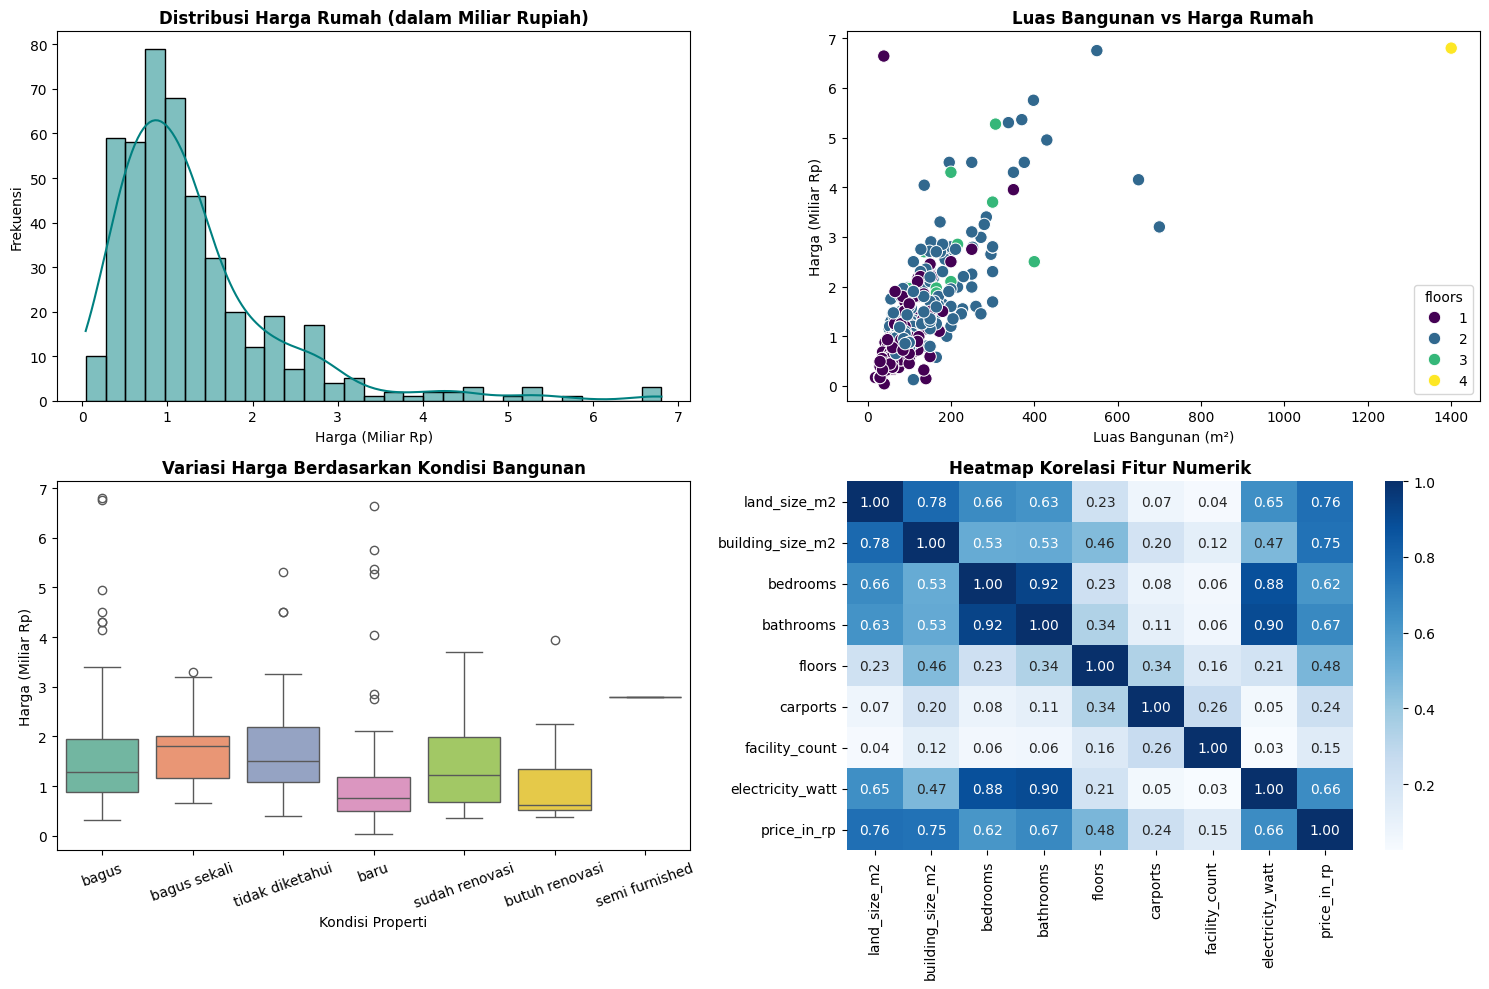

In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 4: EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI
# ------------------------------------------------------------------------------
# Konversi kolom target ke numerik terlebih dahulu untuk menghindari TypeError
clean_df[target] = pd.to_numeric(clean_df[target], errors='coerce')

plt.figure(figsize=(15, 10))

# 3.1 Distribusi Harga Properti
plt.subplot(2, 2, 1)
sns.histplot(clean_df[target] / 1e9, kde=True, color='teal')
plt.title('Distribusi Harga Rumah (dalam Miliar Rupiah)', fontsize=12, fontweight='bold')
plt.xlabel('Harga (Miliar Rp)')
plt.ylabel('Frekuensi')

# 3.2 Hubungan Luas Bangunan vs Harga
plt.subplot(2, 2, 2)
sns.scatterplot(x='building_size_m2', y=clean_df[target]/1e9, data=clean_df, hue='floors', palette='viridis', s=80)
plt.title('Luas Bangunan vs Harga Rumah', fontsize=12, fontweight='bold')
plt.xlabel('Luas Bangunan (m²)')
plt.ylabel('Harga (Miliar Rp)')

# 3.3 Boxplot Harga Berdasarkan Kondisi Properti
plt.subplot(2, 2, 3)
sns.boxplot(x='property_condition', y=clean_df[target]/1e9, data=clean_df, palette='Set2')
plt.title('Variasi Harga Berdasarkan Kondisi Bangunan', fontsize=12, fontweight='bold')
plt.xlabel('Kondisi Properti')
plt.ylabel('Harga (Miliar Rp)')
plt.xticks(rotation=20)

# 3.4 Matriks Korelasi Fitur Numerik
plt.subplot(2, 2, 4)
corr = clean_df[features_num + [target]].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', cbar=True)
plt.title('Heatmap Korelasi Fitur Numerik', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 5: PREPROCESSING & TRAIN-TEST SPLIT
# ------------------------------------------------------------------------------
X = clean_df[features_num + features_cat]
y = clean_df[target]

# Pipeline Preprocessing Numerik & Kategorikal
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, features_num),
        ('cat', cat_transformer, features_cat)
    ]
)

# Split data 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Jumlah Data Latih: {X_train.shape[0]} sampel")
print(f"Jumlah Data Uji  : {X_test.shape[0]} sampel\n")

Jumlah Data Latih: 400 sampel
Jumlah Data Uji  : 100 sampel



In [ ]:
# Install xgboost
!pip install -q xgboost

In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 6: MELATIH BEBERAPA PEMODELAN TERMASUK XGBOOST
# ------------------------------------------------------------------------------
import xgboost as xgb

# Memastikan tidak ada data NaN pada target y_train dan y_test sebelum fitting
train_mask = ~y_train.isna()
test_mask = ~y_test.isna()

X_train_clean = X_train[train_mask]
y_train_clean = y_train[train_mask]

X_test_clean = X_test[test_mask]
y_test_clean = y_test[test_mask]

# Definisikan model, termasuk XGBoost
models = {
    'Multiple Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost Regressor': xgb.XGBRegressor(n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42)
}

results = []

for name, model in models.items():
    # Buat full pipeline
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    pipe.fit(X_train_clean, y_train_clean)

    y_pred_train = pipe.predict(X_train_clean)
    y_pred_test = pipe.predict(X_test_clean)

    r2_train = r2_score(y_train_clean, y_pred_train)
    r2_test = r2_score(y_test_clean, y_pred_test)
    mae_test = mean_absolute_error(y_test_clean, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test_clean, y_pred_test))
    mape_test = np.mean(np.abs((y_test_clean - y_pred_test) / y_test_clean)) * 100

    results.append({
        'Model': name,
        'R2 Train': r2_train,
        'R2 Test': r2_test,
        'MAE (Rp)': mae_test,
        'RMSE (Rp)': rmse_test,
        'MAPE (%)': mape_test
    })

df_results = pd.DataFrame(results)
display(df_results.style.format({
    'R2 Train': '{:.3f}',
    'R2 Test': '{:.3f}',
    'MAE (Rp)': 'Rp {:,.0f}',
    'RMSE (Rp)': 'Rp {:,.0f}',
    'MAPE (%)': '{:.2f}%'
}))

,Model,R2 Train,R2 Test,MAE (Rp),RMSE (Rp),MAPE (%)
0,Multiple Linear Regression,0.760,0.541,"Rp 368,647,750","Rp 753,967,496",32.09%
1,Ridge Regression,0.760,0.541,"Rp 367,009,317","Rp 753,347,209",31.80%
2,Random Forest Regressor,0.964,0.551,"Rp 315,296,264","Rp 745,260,044",21.55%
3,Gradient Boosting Regressor,0.959,0.565,"Rp 311,461,815","Rp 733,828,066",23.39%
4,XGBoost Regressor,0.925,0.551,"Rp 326,076,907","Rp 745,199,664",26.23%


In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 7 : FOKUS PEMODELAN & OPTIMASI DENGAN XGBOOST REGRESSOR
# ------------------------------------------------------------------------------
import xgboost as xgb

# 1. Definisikan Hyperparameter XGBoost yang optimal untuk mencegah overfitting pada dataset kecil
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=4,          # Batasi kedalaman pohon agar tidak terlalu overfit
    learning_rate=0.08,   # Kecepatan belajar yang stabil
    subsample=0.8,        # Menggunakan 80% sampel untuk setiap pohon
    colsample_bytree=0.8, # Menggunakan 80% fitur untuk setiap pohon
    random_state=42
)

# 2. Buat Pipeline khusus XGBoost
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', xgb_model)
])

# 3. Latih Model
xgb_pipeline.fit(X_train_clean, y_train_clean)

# 4. Prediksi
y_pred_train_xgb = xgb_pipeline.predict(X_train_clean)
y_pred_test_xgb = xgb_pipeline.predict(X_test_clean)

# 5. Hitung Metrik Evaluasi
r2_train_xgb = r2_score(y_train_clean, y_pred_train_xgb)
r2_test_xgb = r2_score(y_test_clean, y_pred_test_xgb)
mae_test_xgb = mean_absolute_error(y_test_clean, y_pred_test_xgb)
rmse_test_xgb = np.sqrt(mean_squared_error(y_test_clean, y_pred_test_xgb))
mape_test_xgb = np.mean(np.abs((y_test_clean - y_pred_test_xgb) / y_test_clean)) * 100

# Tampilkan Hasil
print("=== PERFORMA MODEL XGBOOST REGRESSOR ===")
print(f"R² Score (Data Latih) : {r2_train_xgb:.3f}")
print(f"R² Score (Data Uji)   : {r2_test_xgb:.3f}")
print(f"MAE                   : Rp {mae_test_xgb:,.0f}")
print(f"RMSE                  : Rp {rmse_test_xgb:,.0f}")
print(f"MAPE                  : {mape_test_xgb:.2f}%")

=== PERFORMA MODEL XGBOOST REGRESSOR ===
R² Score (Data Latih) : 0.971
R² Score (Data Uji)   : 0.571
MAE                   : Rp 306,269,612
RMSE                  : Rp 728,738,036
MAPE                  : 23.76%


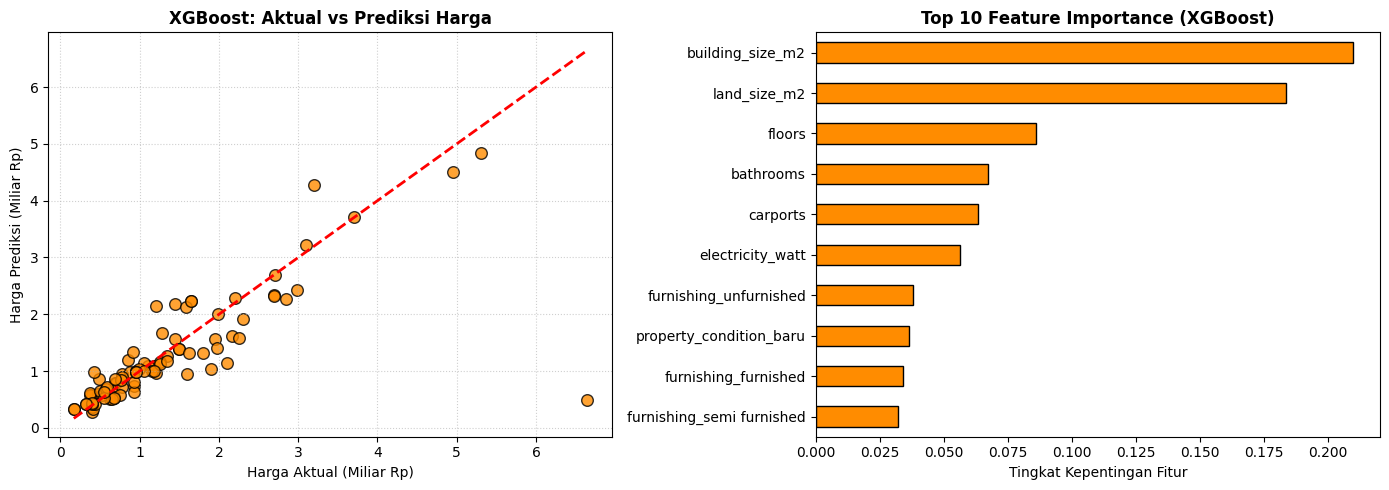

In [ ]:
# ------------------------------------------------------------------------------
# BAGIAN 8 : FOKUS Visualisasi Khusus XGBOOST REGRESSOR
# ------------------------------------------------------------------------------
# Visualisasi Khusus XGBoost
plt.figure(figsize=(14, 5))

# Subplot 1: Aktual vs Prediksi XGBoost
plt.subplot(1, 2, 1)
plt.scatter(y_test_clean / 1e9, y_pred_test_xgb / 1e9, color='darkorange', alpha=0.8, edgecolor='k', s=70)
plt.plot([y_test_clean.min()/1e9, y_test_clean.max()/1e9], [y_test_clean.min()/1e9, y_test_clean.max()/1e9], 'r--', lw=2)
plt.title('XGBoost: Aktual vs Prediksi Harga', fontsize=12, fontweight='bold')
plt.xlabel('Harga Aktual (Miliar Rp)')
plt.ylabel('Harga Prediksi (Miliar Rp)')
plt.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Feature Importance XGBoost
plt.subplot(1, 2, 2)
# Ekstraksi nama fitur pasca preprocessing
encoded_cat_names = xgb_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(features_cat)
all_feature_names = features_num + list(encoded_cat_names)
importances_xgb = xgb_pipeline.named_steps['regressor'].feature_importances_

feat_imp_xgb = pd.Series(importances_xgb, index=all_feature_names).sort_values(ascending=False).head(10)
feat_imp_xgb.plot(kind='barh', color='darkorange', edgecolor='black')
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importance (XGBoost)', fontsize=12, fontweight='bold')
plt.xlabel('Tingkat Kepentingan Fitur')

plt.tight_layout()
plt.show()

In [ ]:
# Simpan model `xgb_pipeline` ke file pickle

import pickle
import os

# Nama file penyimpanan
model_filename = 'xgb_house_price_model.pkl'

# Menyimpan pipeline XGBoost ke file pickle
with open(model_filename, 'wb') as file:
    pickle.dump(xgb_pipeline, file)

# Verifikasi file berhasil tersimpan
if os.path.exists(model_filename):
    file_size_kb = os.path.getsize(model_filename) / 1024
    print(f"✓ Sukses! Model XGBoost berhasil disimpan ke: '{model_filename}'")
    print(f"✓ Ukuran File: {file_size_kb:.2f} KB")
else:
    print("✗ Gagal menyimpan model.")

✓ Sukses! Model XGBoost berhasil disimpan ke: 'xgb_house_price_model.pkl'
✓ Ukuran File: 163.43 KB
